<a href="https://colab.research.google.com/github/lourdescufre-remoto-dot/coffee-sales-analysis/blob/main/coffee_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coffee Sales Analysis
## Análisis de ventas de una cafetería para mejorar la toma de decisiones
* **Autora**: Lourdes Cufre
* **Contacto**: lourdescufre.remoto@gmail.com
  
-------
## Descripción del proyecto
Este proyecto presenta un análisis exploratorio de un conjunto de datos de ventas para entender qué se vende, cuándo y cómo pagan los clientes, y convertir esos datos en recomendaciones concretas.

## Preguntas que responde este análisis
- ¿Cuáles son los productos más y menos vendidos?
- ¿Cómo evolucionan las ventas a lo largo del tiempo?
- ¿En qué horarios o días se vende más?
- ¿Qué métodos de pago prefieren los clientes?
- ¿Qué productos generan más ingresos?
  
## Datos
- **Dataset**: [Coffee Sales](https://www.kaggle.com/datasets/ihelon/coffee-sales)
- **Tamaño final**: 3896 registros y 6 columnas, después de unir los archivos y limpiar los datos (9 columnas en el CSV guardado, al agregar `hora`, `dia_semana` y `mes`).
- **Período**: 2024-03-01 a 2025-03-23

## Contenido del notebook
1. Carga y exploración inicial
2. Limpieza de datos
3. Análisis de ventas
4. Hallazgos y recomendaciones

## Herramientas

`Python` · `pandas` · `matplotlib` · `seaborn` · `Jupyter Notebook`


# 1. Carga y exploración inicial

## 1.1 Librerías
Para el análisis se usan:

* `pandas` : manejo de datos
* `matplotlib` y `seaborn` : visualizaciones


In [187]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
COLOR = "#8c5a3c"

## 1.2 Carga de datos
En esta etapa se cargan los dos archivos CSV para comenzar la exploración de las ventas de la cafetería.

In [188]:
df1 = pd.read_csv("/content/index_1.csv")
df2 = pd.read_csv("/content/index_2.csv")

## 1.3 Revisión y unión de los archivos
Antes de unir los dos archivos, se revisan las columnas, los períodos y si hay ventas repetidas entre ambos, para no duplicar ventas.

In [189]:
print ("Columnas df1:", df1.columns.tolist())
print ("Columnas df2:", df2.columns.tolist())
print("¿Mismas columnas?", list(df1.columns) == list(df2.columns))

print("\ndf1:", df1.shape)
print("\ndf2:", df2.shape)

display(df1.head())
display(df2.head())


Columnas df1: ['date', 'datetime', 'cash_type', 'card', 'money', 'coffee_name']
Columnas df2: ['date', 'datetime', 'cash_type', 'money', 'coffee_name']
¿Mismas columnas? False

df1: (3636, 6)

df2: (262, 5)


,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


,date,datetime,cash_type,money,coffee_name
0,2025-02-08,2025-02-08 14:26:04,cash,15.0,Tea
1,2025-02-08,2025-02-08 14:28:26,cash,15.0,Tea
2,2025-02-08,2025-02-08 14:33:04,card,20.0,Espresso
3,2025-02-08,2025-02-08 15:51:04,card,30.0,Chocolate with coffee
4,2025-02-08,2025-02-08 16:35:01,cash,27.0,Chocolate with milk


In [190]:
# Convertir a datetime primero
df1["date"] = pd.to_datetime(df1["date"])
df2["date"] = pd.to_datetime(df2["date"])

# Imprimir los rangos correctamente usando datetime
print("df1:", df1["date"].min().date(), "a", df1["date"].max().date())
print("df2:", df2["date"].min().date(), "a", df2["date"].max().date())

# Productos y métodos de pago en cada archivo
print("\nProductos df1:", sorted(df1["coffee_name"].unique()))
print("Productos df2:", sorted(df2["coffee_name"].unique()))
print("\nPagos df1:", df1["cash_type"].unique())
print("Pagos df2:", df2["cash_type"].unique())

# Precio promedio por producto en cada archivo
print("\nPrecio promedio df1")
print(df1.groupby("coffee_name")["money"].mean().round(1))
print("\nPrecio promedio df2")
print(df2.groupby("coffee_name")["money"].mean().round(1))

df1: 2024-03-01 a 2025-03-23
df2: 2025-02-08 a 2025-03-23

Productos df1: ['Americano', 'Americano with Milk', 'Cappuccino', 'Cocoa', 'Cortado', 'Espresso', 'Hot Chocolate', 'Latte']
Productos df2: ['Americano', 'Americano with milk', 'Cappuccino', 'Caramel', 'Caramel coffee', 'Caramel with Irish whiskey', 'Caramel with chocolate', 'Caramel with milk', 'Chocolate', 'Chocolate with coffee', 'Chocolate with milk', 'Coffee with Irish whiskey', 'Coffee with chocolate', 'Double Irish whiskey', 'Double chocolate', 'Double espresso', 'Double espresso with milk', 'Double ristretto', 'Double vanilla', 'Espresso', 'Hot milkshake', 'Irish whiskey', 'Irish whiskey with milk', 'Irish with chocolate', 'Latte', 'Mochaccino', 'Super chocolate', 'Tea', 'Vanilla coffee', 'Vanilla with Irish whiskey']

Pagos df1: ['card' 'cash']
Pagos df2: ['cash' 'card']

Precio promedio df1
coffee_name
Americano              26.1
Americano with Milk    30.7
Cappuccino             36.0
Cocoa                  35.7
Cortad

In [191]:
inicio, fin = pd.to_datetime("2025-02-08"), pd.to_datetime("2025-03-23")
fechas1 = pd.to_datetime(df1["date"])
comun1 = df1[(fechas1 >= inicio) & (fechas1 <= fin)]

print("Ventas de df1 en el período en común:", len(comun1))
print("Ventas de df2 en el período en común:", len(df2))

horas1 = set(pd.to_datetime(comun1["datetime"]).dt.floor("s"))
horas2 = set(pd.to_datetime(df2["datetime"]).dt.floor("s"))
print("Ventas con la misma fecha y hora en ambos:", len(horas1 & horas2))

Ventas de df1 en el período en común: 635
Ventas de df2 en el período en común: 262
Ventas con la misma fecha y hora en ambos: 0


In [192]:
# Marcamos de qué archivo viene cada venta
df1["origen"] = "archivo_1"
df2["origen"] = "archivo_2"

# Eliminamos la columna 'card'
df1 = df1.drop(columns=["card"], errors="ignore")
df2 = df2.drop(columns=["card"], errors="ignore")

# Unimos los archivos ya limpios
df = pd.concat([df1, df2], ignore_index=True)

# Unificamos mayúsculas en los nombres de los productos
df["coffee_name"] = df["coffee_name"].str.strip().str.title()

# Convertimos la fecha y hora a formato datetime
df["datetime"] = pd.to_datetime(df["datetime"], format="mixed")

print("Dimensiones de df:", df.shape)
print("\nVentas por origen:")
print(df["origen"].value_counts())
print("\nValores faltantes:")
print(df.isnull().sum())
print("\nProductos distintos:", df["coffee_name"].nunique())


Dimensiones de df: (3898, 6)

Ventas por origen:
origen
archivo_1    3636
archivo_2     262
Name: count, dtype: int64

Valores faltantes:
date           0
datetime       0
cash_type      0
money          0
coffee_name    0
origen         0
dtype: int64

Productos distintos: 33


### Interpretación
Los dos archivos tienen períodos que se superponen (del 8/2/2025 al 23/3/2025). Al comparar las fechas y horas, no se encontraron coincidencias entre ambos archivos. Sin embargo, al revisar el dataset unificado se detectaron dos filas duplicadas, que se analizaron y eliminaron en la sección de limpieza de datos.

Además, los archivos presentan catálogos de productos diferentes, por lo que se conservó una columna para identificar el origen de cada venta.

Para unirlos:
- Se agregó la columna `origen`, para identificar de qué archivo proviene cada registro.
- Se eliminó la columna `card`, que no existe en el segundo archivo y no se utiliza en este análisis.
- Se unificó el formato de los nombres de los productos.

*El dataset unificado contiene inicialmente 3.898 registros y 33 productos distintos. Después de eliminar las dos filas duplicadas, el dataset final queda con 3.896 ventas.*


# 2. Limpieza de datos

## 2.1 Estructura del dataset
Se revisa la estructura del dataset unificado: tipos de datos, estadísticas de las ventas y posibles problemas antes de analizar.

In [193]:
df.info()
print ("\nResumen estadístico de las ventas:")
display(df["money"].describe())

print ("\nFilas duplicadas:", df.duplicated().sum())

print ("\nVentas por método de pago:")
print(df["cash_type"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3898 entries, 0 to 3897
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3898 non-null   datetime64[ns]
 1   datetime     3898 non-null   datetime64[ns]
 2   cash_type    3898 non-null   object        
 3   money        3898 non-null   float64       
 4   coffee_name  3898 non-null   object        
 5   origen       3898 non-null   object        
dtypes: datetime64[ns](2), float64(1), object(3)
memory usage: 182.8+ KB

Resumen estadístico de las ventas:


,money
count,3898.00000
mean,31.38060
std,5.06461
min,15.00000
25%,27.92000
50%,32.82000
75%,35.76000
max,40.00000



Filas duplicadas: 2

Ventas por método de pago:
cash_type
card    3729
cash     169
Name: count, dtype: int64


### Interpretación
- **Ventas iniciales:** 3.898 registros antes de eliminar los duplicados.
- **Precio por venta:** los importes se encuentran entre 15 y 40, con un promedio aproximado de 31,4 unidades monetarias.
- **Métodos de pago:** la mayoría de las ventas se realizan con tarjeta (95,7 %), mientras que el efectivo representa el 4,3 %.
- **Filas duplicadas:** se detectaron dos filas repetidas, que se revisan en la siguiente sección antes de eliminarlas.

En esta etapa se identificaron los principales aspectos que debían verificarse antes de realizar el análisis definitivo.

## 2.2 Filas duplicadas
Se revisan las dos filas repetidas para decidir si corresponde eliminarlas.

In [194]:
df[df.duplicated(keep=False)]

,date,datetime,cash_type,money,coffee_name,origen
3746,2025-02-26,2025-02-26 09:41:12,cash,25.0,Americano With Milk,archivo_2
3747,2025-02-26,2025-02-26 09:41:12,cash,25.0,Americano With Milk,archivo_2
3891,2025-03-23,2025-03-23 10:25:48,cash,25.0,Americano With Milk,archivo_2
3892,2025-03-23,2025-03-23 10:25:48,cash,25.0,Americano With Milk,archivo_2


In [195]:
# Eliminamos las filas repetidas (se conserva la primera de cada par)
df = df.drop_duplicates().reset_index(drop=True)
print ("Dimensiones de df:", df.shape)
print ("Filas duplicadas:", df.duplicated().sum())

Dimensiones de df: (3896, 6)
Filas duplicadas: 0


### Interpretación
Se detectaron dos filas duplicadas, correspondientes a dos pares de registros con la misma fecha y hora, producto, importe y método de pago.

Se revisaron los registros y se decidió eliminar una fila de cada par para evitar contabilizar dos veces las mismas operaciones. Esta decisión se basa en la coincidencia de todos los campos registrados.

Después de la limpieza, el dataset quedó con **3.896 ventas y sin filas duplicadas exactas**.

## 2.3 Columnas del tiempo
Para analizar los horarios y la evolución de las ventas, se crean nuevas columnas a partir de la fecha y hora de cada venta: hora, día de la semana y mes.

In [196]:
df["hora"] = df["datetime"].dt.hour
df["mes"] = df["datetime"].dt.to_period("M").astype(str)

# Día de la semana español ordenado de lunes a domingo
orden_dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

df["dia_semana"] = df["datetime"].dt.dayofweek.map(lambda n:orden_dias[n])
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=orden_dias, ordered=True)

print("Días sin valor:", df["dia_semana"].isnull().sum())
print(df["dia_semana"].value_counts().sort_index())

df[["datetime", "hora", "dia_semana", "mes"]].head()

Días sin valor: 0
dia_semana
Lunes        591
Martes       604
Miércoles    552
Jueves       540
Viernes      586
Sábado       531
Domingo      492
Name: count, dtype: int64


,datetime,hora,dia_semana,mes
0,2024-03-01 10:15:50.520,10,Viernes,2024-03
1,2024-03-01 12:19:22.539,12,Viernes,2024-03
2,2024-03-01 12:20:18.089,12,Viernes,2024-03
3,2024-03-01 13:46:33.006,13,Viernes,2024-03
4,2024-03-01 13:48:14.626,13,Viernes,2024-03


### Interpretación
A partir de la fecha y hora de cada venta se crearon tres columnas nuevas: `hora`, `dia_semana` y `mes`.
Con ellas se pueden analizar los horarios, los días y la evolución de las ventas en el tiempo.

## 2.4 Guardar el dataset limpio
Se guarda el dataset ya limpio en un archivo CSV.

In [197]:
df.to_csv("coffee_sales_cleaned.csv", index=False)

from google.colab import files
#files.download("coffee_sales_cleaned.csv")

# 3. Análisis de ventas


## 3.1 Productos más y menos vendidos
Se cuenta cuántas ventas tuvo cada producto para identificar los más y los menos demandados.

### Productos más vendidos

Los 8 más vendidos:
coffee_name
Americano With Milk    866
Latte                  806
Americano              593
Cappuccino             517
Cortado                292
Hot Chocolate          282
Cocoa                  243
Espresso               152
Name: count, dtype: int64


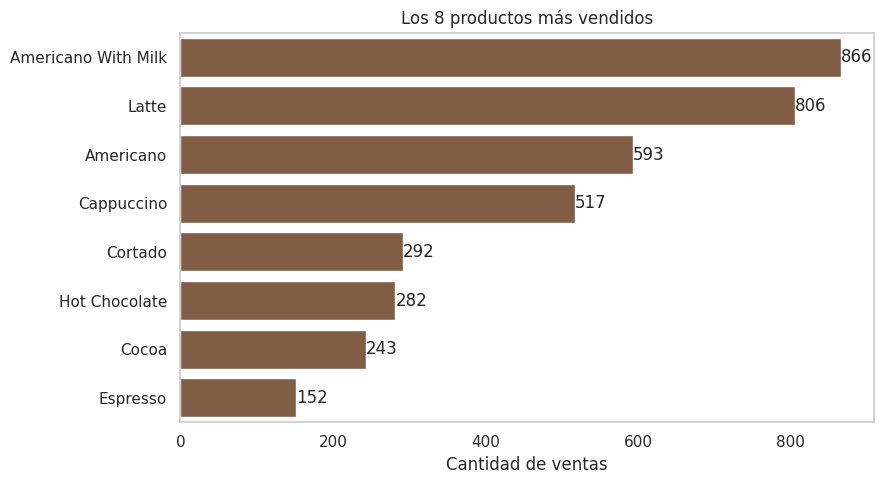

In [198]:
ventas_por_producto = df["coffee_name"].value_counts()

print ("Los 8 más vendidos:")
print(ventas_por_producto.head(8))

# Gráfico de los 8 más vendidos
plt.figure(figsize=(9,5))
ax = sns.barplot(x=ventas_por_producto.head(8).values,
                y=ventas_por_producto.head(8).index,
                color="#8c5a3c")

ax.bar_label(ax.containers[0])

plt.title("Los 8 productos más vendidos")
plt.xlabel("Cantidad de ventas")
plt.ylabel("")
plt.tight_layout()
ax.grid(False)
plt.savefig("grafico_top1.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación
* **Los más vendidos:** Americano With Milk (866) y Latte (806) están primeros y juntos suman casi el 43 % de las ventas.

* **Los 4 principales:**
- Americano With Milk:    866
- Latte:                  806
- Americano:              593
- Cappuccino:             517

*Concentran el 71,4 % de las ventas.*

* **El resto del menú:** el dataset tiene 33 productos, y estos 8 concentran el 96,3 % de las ventas. Los otros 25 aparecen solo en el segundo archivo (unas seis semanas de datos) y suman 145 ventas, por lo que no se pueden comparar de forma justa.

### Productos menos vendidos
Para comparar de forma justa, se analizan solo los 8 productos del primer archivo, que cubre un año completo de ventas.

Ventas por producto (primer archivo):
coffee_name
Americano With Milk    824
Latte                  782
Americano              578
Cappuccino             501
Cortado                292
Hot Chocolate          282
Cocoa                  243
Espresso               134
Name: count, dtype: int64


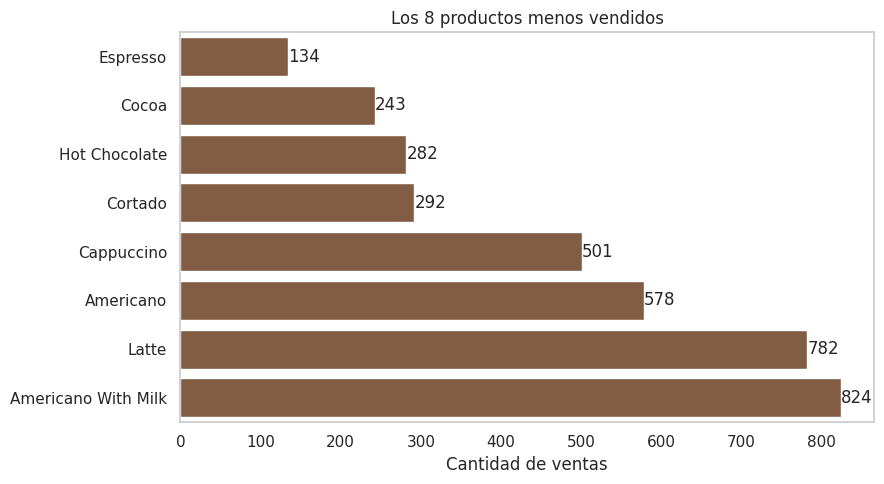

In [199]:
ventas_archivo1 = df[df["origen"] == "archivo_1"]["coffee_name"].value_counts()
print("Ventas por producto (primer archivo):")
print(ventas_archivo1)

# Gráfico de menor a mayor
ventas_ordenadas = ventas_archivo1.sort_values()

plt.figure(figsize=(9,5))
ax = sns.barplot(x=ventas_ordenadas.values,
                y=ventas_ordenadas.index,
                color="#8c5a3c")

ax.bar_label(ax.containers[0])

plt.title("Los 8 productos menos vendidos")
plt.xlabel("Cantidad de ventas")
plt.ylabel("")
plt.tight_layout()
ax.grid(False)
plt.savefig("grafico_top2.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación
* **Los menos vendidos:**
- Espresso:               134
- Cocoa:                  243
- Hot Chocolate:          282
- Cortado:                292
  
* **Diferencia con los más vendidos:** Americano With Milk vende más de 6 veces lo que el Espresso (824 contra 134).

## 3.2 Evolución de las ventas
Se cuenta cuántas ventas hubo cada mes para ver cómo cambia la demanda a lo largo del período.

Ventas por mes:
origen   archivo_1  archivo_2  total  dias_con_ventas  promedio_diario
mes                                                                   
2024-03        206          0    206               31              6.6
2024-04        196          0    196               30              6.5
2024-05        267          0    267               28              9.5
2024-06        227          0    227               30              7.6
2024-07        237          0    237               31              7.6
2024-08        272          0    272               31              8.8
2024-09        344          0    344               30             11.5
2024-10        426          0    426               31             13.7
2024-11        259          0    259               29              8.9
2024-12        259          0    259               31              8.4
2025-01        201          0    201               28              7.2
2025-02        423        137    560               28        

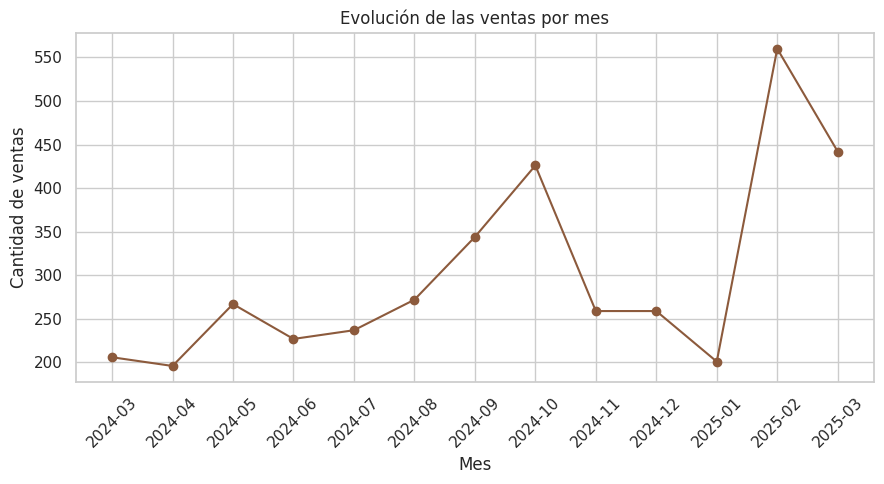

In [200]:
ventas_mes = df.groupby("mes").size()
print("Ventas por mes:")

tabla = df.groupby(["mes", "origen"]).size().unstack(fill_value=0)
tabla["total"] = tabla.sum(axis=1)
tabla["dias_con_ventas"] = df.groupby("mes")["date"].nunique()
tabla["promedio_diario"] = (tabla["total"] / tabla["dias_con_ventas"]).round(1)
print(tabla)

plt.figure(figsize=(9,5))
plt.plot(ventas_mes.index, ventas_mes.values, marker="o", color="#8c5a3c")

plt.title("Evolución de las ventas por mes")
plt.xlabel("Mes")
plt.ylabel("Cantidad de ventas")
plt.xticks(rotation=45)
plt.tight_layout()
ax.grid(False)
plt.savefig("grafico_top3.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación
* **Crecimiento:** las ventas aumentaron de 206 en marzo de 2024 a 426 en octubre de 2024, más del doble en ese período.
* **Baja de fin de año:** de noviembre a enero bajan a entre 259 y 201 ventas por mes.
* **Febrero y marzo de 2025:** son los meses con más ventas (560 y 442). Parte de la suba viene del segundo archivo, que aporta 137 y 123 ventas, pero el primer archivo por sí solo ya vende a un ritmo parecido al de octubre.
* **Marzo está incompleto:** los datos llegan hasta el 23, pero el ritmo diario es parecido al de febrero.

## 3.3 Horarios y días de mayor venta
Se cuenta cuántas ventas hubo por hora y por día de la semana para ver cuándo se concentra la demanda.

Ventas por hora:
hora
6       5
7      99
8     246
9     257
10    362
11    316
12    271
13    241
14    245
15    267
16    307
17    267
18    247
19    253
20    177
21    210
22    123
23      3
dtype: int64

Ventas por día de la semana:
dia_semana
Lunes        591
Martes       604
Miércoles    552
Jueves       540
Viernes      586
Sábado       531
Domingo      492
Name: count, dtype: int64


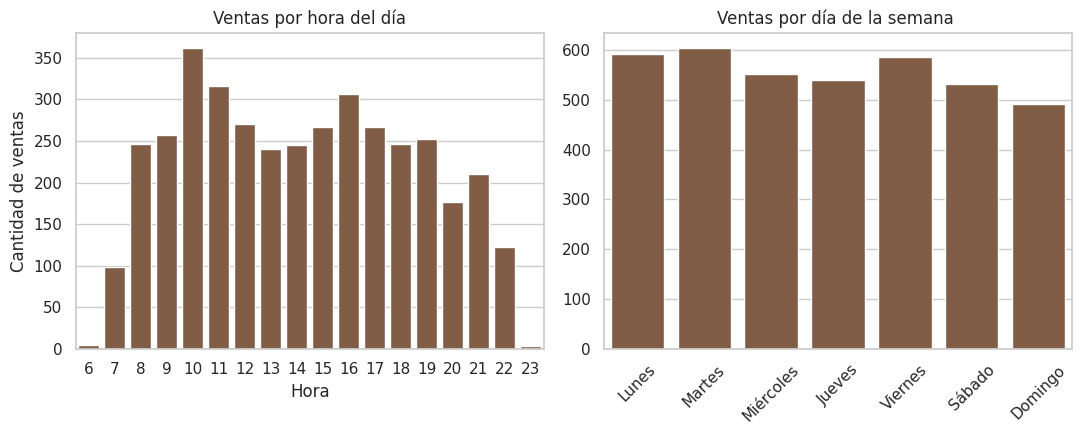

In [201]:
ventas_hora = df.groupby("hora").size()
ventas_dia = df["dia_semana"].value_counts().sort_index()

print("Ventas por hora:")
print(ventas_hora)
print("\nVentas por día de la semana:")
print(ventas_dia)

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
sns.barplot(x=ventas_hora.index, y=ventas_hora.values, color="#8c5a3c", ax=axes[0])
axes[0].set_title("Ventas por hora del día")
axes[0].set_xlabel("Hora")
axes[0].set_ylabel("Cantidad de ventas")

sns.barplot(x=ventas_dia.index, y=ventas_dia.values, color="#8c5a3c", ax=axes[1])
axes[1].set_title("Ventas por día de la semana ")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
ax.grid(False)
plt.savefig("grafico_top4.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretación
**Ventas por hora:**
* **Mayor actividad:** 10 h (362 ventas), 11 h (316) y 16 h (307). Hay un pico fuerte a media mañana y uno más chico a las 16 h.
* **Menor actividad:** 23 h (3 ventas) y 6 h (5).

**Ventas por día de la semana:**
* **Más ventas:** martes (604), lunes (591) y viernes (586).
* **Menos ventas:** domingo (492).
* **Diferencia entre días:** el domingo vende alrededor de un 19 % menos que el martes, pero en general la demanda es bastante pareja durante toda la semana.

## 3.4 Métodos de pago
Se analiza cómo pagan los clientes y si el método cambia según el archivo de origen.


Ventas por método de pago:
cash_type
Tarjeta     3729
Efectivo     167
Name: count, dtype: int64

Porcentaje:
cash_type
Tarjeta     95.7
Efectivo     4.3
Name: count, dtype: float64

Métodos de pago por archivo:
cash_type  card  cash
origen               
archivo_1  3547    89
archivo_2   182    78


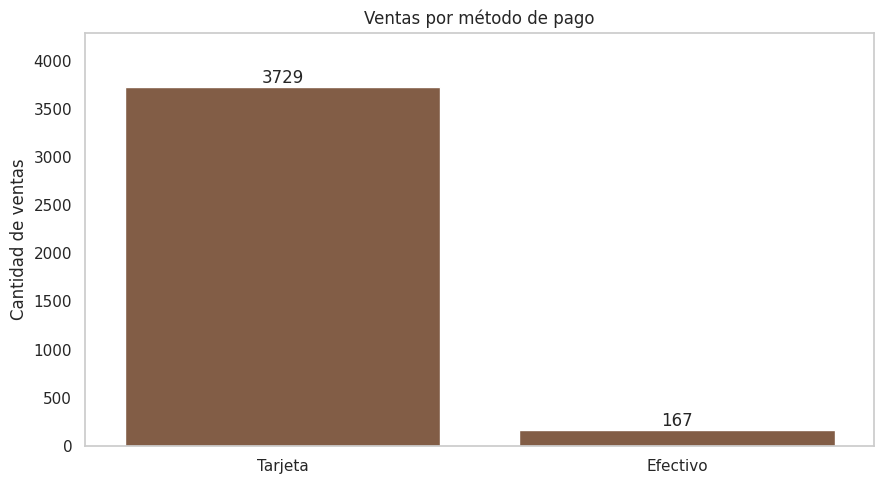

In [202]:
pagos = df["cash_type"].value_counts().rename({"card": "Tarjeta", "cash": "Efectivo"})

print ("Ventas por método de pago:")
print (pagos)

print ("\nPorcentaje:")
print((pagos / len(df) * 100).round(1))

print ("\nMétodos de pago por archivo:")
print(pd.crosstab(df["origen"], df["cash_type"]))


plt.figure(figsize=(9,5))
ax = sns.barplot(x=pagos.index, y=pagos.values, color="#8c5a3c")
ax.bar_label(ax.containers[0])

plt.ylim(0, pagos.max() * 1.15 )
plt.title("Ventas por método de pago")
plt.xlabel("")
plt.ylabel("Cantidad de ventas")
ax.grid(False)
plt.savefig("grafico_top5.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()



### Interpretación
- **Método de pago más utilizado:** la tarjeta, con 3.729 ventas (95,7 %), frente a 167 ventas en efectivo (4,3 %).
- **Diferencias entre archivos:** en el primer archivo predomina el pago con tarjeta (97,6 %). En el segundo archivo, el efectivo representa aproximadamente el 30 % (78 de 260 ventas).
- **Posible explicación:** las diferencias en los métodos de pago podrían estar relacionadas con las características de cada fuente de datos. Sin información adicional, no es posible confirmar la causa.

Los porcentajes generales se calcularon sobre el dataset unificado después de la limpieza.

## 3.5 Ingresos por producto
Hasta acá se midió la **cantidad de ventas**. Esta sección mide **cuánto dinero deja cada producto**, que puede dar un ranking distinto.

Como en los productos menos vendidos, se usa solo `archivo_1`: tiene un año completo y sus 8 productos son comparables. Los 25 productos del segundo archivo solo cubren seis semanas.

Ingresos por producto (primer archivo)
                     ventas  ingresos  precio_promedio  % de ingresos
coffee_name                                                          
Latte                   782   27866.0             35.6           24.1
Americano With Milk     824   25269.0             30.7           21.9
Cappuccino              501   18034.0             36.0           15.6
Americano               578   15062.0             26.1           13.0
Hot Chocolate           282   10172.0             36.1            8.8
Cocoa                   243    8678.0             35.7            7.5
Cortado                 292    7535.0             25.8            6.5
Espresso                134    2814.0             21.0            2.4


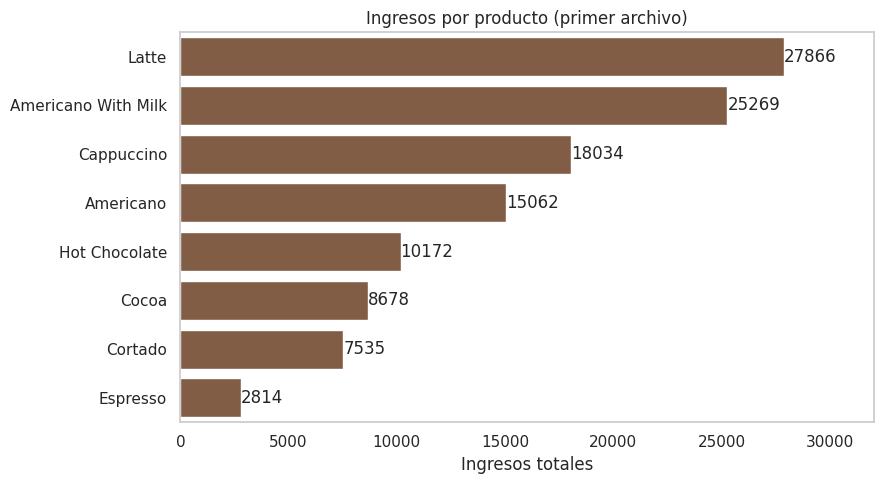

In [203]:
archivo1 = df[df["origen"] == "archivo_1"]

resumen = archivo1.groupby("coffee_name").agg(
    ventas=("money", "size"),
    ingresos=("money", "sum"),
    precio_promedio=("money", "mean")
).sort_values("ingresos", ascending=False)

resumen["ingresos"] = resumen["ingresos"].round(0)
resumen["precio_promedio"] = resumen["precio_promedio"].round(1)
resumen["% de ingresos"] = (resumen["ingresos"] / resumen["ingresos"].sum() * 100).round(1)

print ("Ingresos por producto (primer archivo)")
print(resumen)

plt.figure(figsize=(9,5))
ax = sns.barplot (x=resumen["ingresos"].values,
                 y=resumen.index,
                 color="#8c5a3c")

ax.bar_label(ax.containers[0])

plt.xlim(0, resumen["ingresos"].max() * 1.15)
plt.title("Ingresos por producto (primer archivo)")
plt.xlabel("Ingresos totales")
plt.ylabel("")
ax.grid(False)
plt.savefig("grafico_top6.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

### Interpretación
- **Producto que más ingresos genera:** el Latte ocupa el primer puesto, con 27.866 unidades monetarias, equivalentes al 24,1 % de los ingresos analizados. Aunque el Americano With Milk registra más ventas, el Latte genera mayores ingresos por su precio promedio más alto.
- **Cappuccino frente a Americano:** el Cappuccino genera más ingresos que el Americano, aunque registra menos ventas, debido a su mayor precio promedio.
- **Productos con menores ingresos:** el Cortado ocupa el séptimo puesto por ingresos y el Espresso se encuentra en el último lugar, con una participación del 2,4 %.
- **Concentración de ingresos:** los cuatro productos principales —Latte, Americano With Milk, Cappuccino y Americano— representan el 74,7 % de los ingresos del primer archivo.

**Nota:** este ranking se calcula únicamente con `archivo_1`, que cubre un período más extenso y permite comparar los ocho productos de ese catálogo. Por eso, sus cantidades vendidas no coinciden necesariamente con las del ranking general, que incluye ambos archivos.

# 4. Hallazgos y recomendaciones

## Hallazgos principales

- **Productos más vendidos:** Americano With Milk y Latte lideran las ventas del dataset unificado. Los cuatro productos principales concentran el 71,4 % de las ventas.
- **Ingresos por producto:** el Latte es el producto que más ingresos genera dentro del primer archivo, con el 24,1 % del total analizado. Los cuatro productos principales concentran el 74,7 % de esos ingresos.
- **Horarios y días:** la mayor actividad se registra a las 10 y 11 h, con un pico adicional a las 16 h. El domingo es el día con menos ventas.
- **Métodos de pago:** el 95,7 % de las ventas se realiza con tarjeta, mientras que el 4,3 % se realiza en efectivo.
- **Evolución mensual:** las ventas aumentan durante los primeros meses del período, alcanzan un pico en octubre de 2024 y vuelven a crecer en febrero y marzo de 2025. Marzo está incompleto, ya que los datos llegan hasta el día 23.

## Recomendaciones

- **Stock y menú:** asegurar la disponibilidad de los cuatro productos más vendidos y destacar el Latte y el Cappuccino, que generan mayores ingresos dentro del primer archivo.
- **Horarios:** reforzar la atención a media mañana y a las 16 h. Evaluar si resulta conveniente abrir a las 6 h y cerrar a las 23 h, horarios con menor actividad.
- **Promociones:** evaluar acciones comerciales para los domingos y para enero, uno de los meses con menor ritmo diario (7,2 ventas/día, junto con marzo y abril de 2024). Noviembre y diciembre quedan por encima de esos meses. Con un solo año de datos no se puede confirmar estacionalidad.

**Nota:** el análisis combina dos archivos con períodos y catálogos diferentes. El ranking de ventas utiliza el dataset unificado, mientras que el ranking de ingresos por producto se calcula únicamente con el primer archivo. Los ingresos representan importes de ventas y no equivalen a ganancias, ya que no se descuentan los costos.